1. **lagrangian analysis:** three subplots containing the 50-m advection, in (a) back track, (b) east releasing and (c) north releasing. The figure must contain:
	1. isobaths (200, 1000, 2000, 4000)
	2. coordinates in the left and bottom axis
	3. the releasing point in red
	4. name of main places (Guanabara, Cabo Frio, Cabo São Tomé, Tubarão Bight)

In [2]:
import xarray as xr
import numpy as np
import math
from datetime import timedelta,datetime
from operator import attrgetter
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
import cartopy.crs as ccrs
from matplotlib.patches import Rectangle
import cmocean.cm as cmo

import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import sys
sys.path.insert(0, '/home/danilo/phd/thesis/chapter_colab/scripts/')
from load_profiles import load_vertical_profiles
from utils import subplots_structure

In [3]:
dict_casts = load_vertical_profiles()

# plotting with my functions
zoomed_extent= [-50, -37, -30, -22] #[-45, -39, -27, -22]

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [4]:
zoomed_extent = [-50, -37, -30, -21.5]
zoomed_extent = [-45, -37, -27, -19]

bathy = xr.open_dataset('../data/gebco_updated.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [5]:
experiments = {
    "smax_from_backpropag_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_backpropag_cmems.zarr'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_backpropag_isopycnal": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_backpropag_cmems_isopycnal.zarr/'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_east_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_east_cmems.zarr'),
                'center_launch': [-39, -26.5],
                },
    "smax_from_north_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_north_cmems.zarr'),
                'center_launch': [-40, -22],
                },
}

# Figure Lagrangian results

In [9]:
import numpy as np

def get_hist2d(p, bins=200, extent=None, normalize=True):
    """
    Calcula um histograma 2D de densidade de partículas a partir de um
    Dataset do Parcels.

    Parameters
    ----------
    p : xarray.Dataset
        Dataset de trajetórias do Parcels (com lon, lat).
    bins : int or tuple
        Número de bins em x e y.
    extent : tuple or None
        (xmin, xmax, ymin, ymax). Se None, usa min/max dos dados.
    normalize : bool
        Se True, normaliza o histograma pelo valor máximo.

    Returns
    -------
    x : 1D array
        Centros dos bins em x (lon).
    y : 1D array
        Centros dos bins em y (lat).
    H : 2D array
        Histograma 2D (densidade de partículas).
    """

    # extrai posições (flatten para juntar todas as partículas e tempos)
    xdata = p.lon.values.flatten()
    ydata = p.lat.values.flatten()

    # remove NaNs (partículas mortas, etc.)
    m = np.isfinite(xdata) & np.isfinite(ydata)
    xdata = xdata[m]
    ydata = ydata[m]

    # define limites
    if extent is None:
        xmin, xmax = xdata.min(), xdata.max()
        ymin, ymax = ydata.min(), ydata.max()
    else:
        xmin, xmax, ymin, ymax = extent

    # histograma 2D
    H, xedges, yedges = np.histogram2d(
        xdata,
        ydata,
        bins=bins,
        range=[[xmin, xmax], [ymin, ymax]]
    )

    # normalização
    if normalize and H.max() > 0:
        H = H / H.max()

    # centros dos bins (pcolormesh-friendly)
    x = 0.5 * (xedges[:-1] + xedges[1:])
    y = 0.5 * (yedges[:-1] + yedges[1:])

    # transpose: histogram2d retorna [x, y], pcolormesh espera [y, x]
    return x, y, H.T


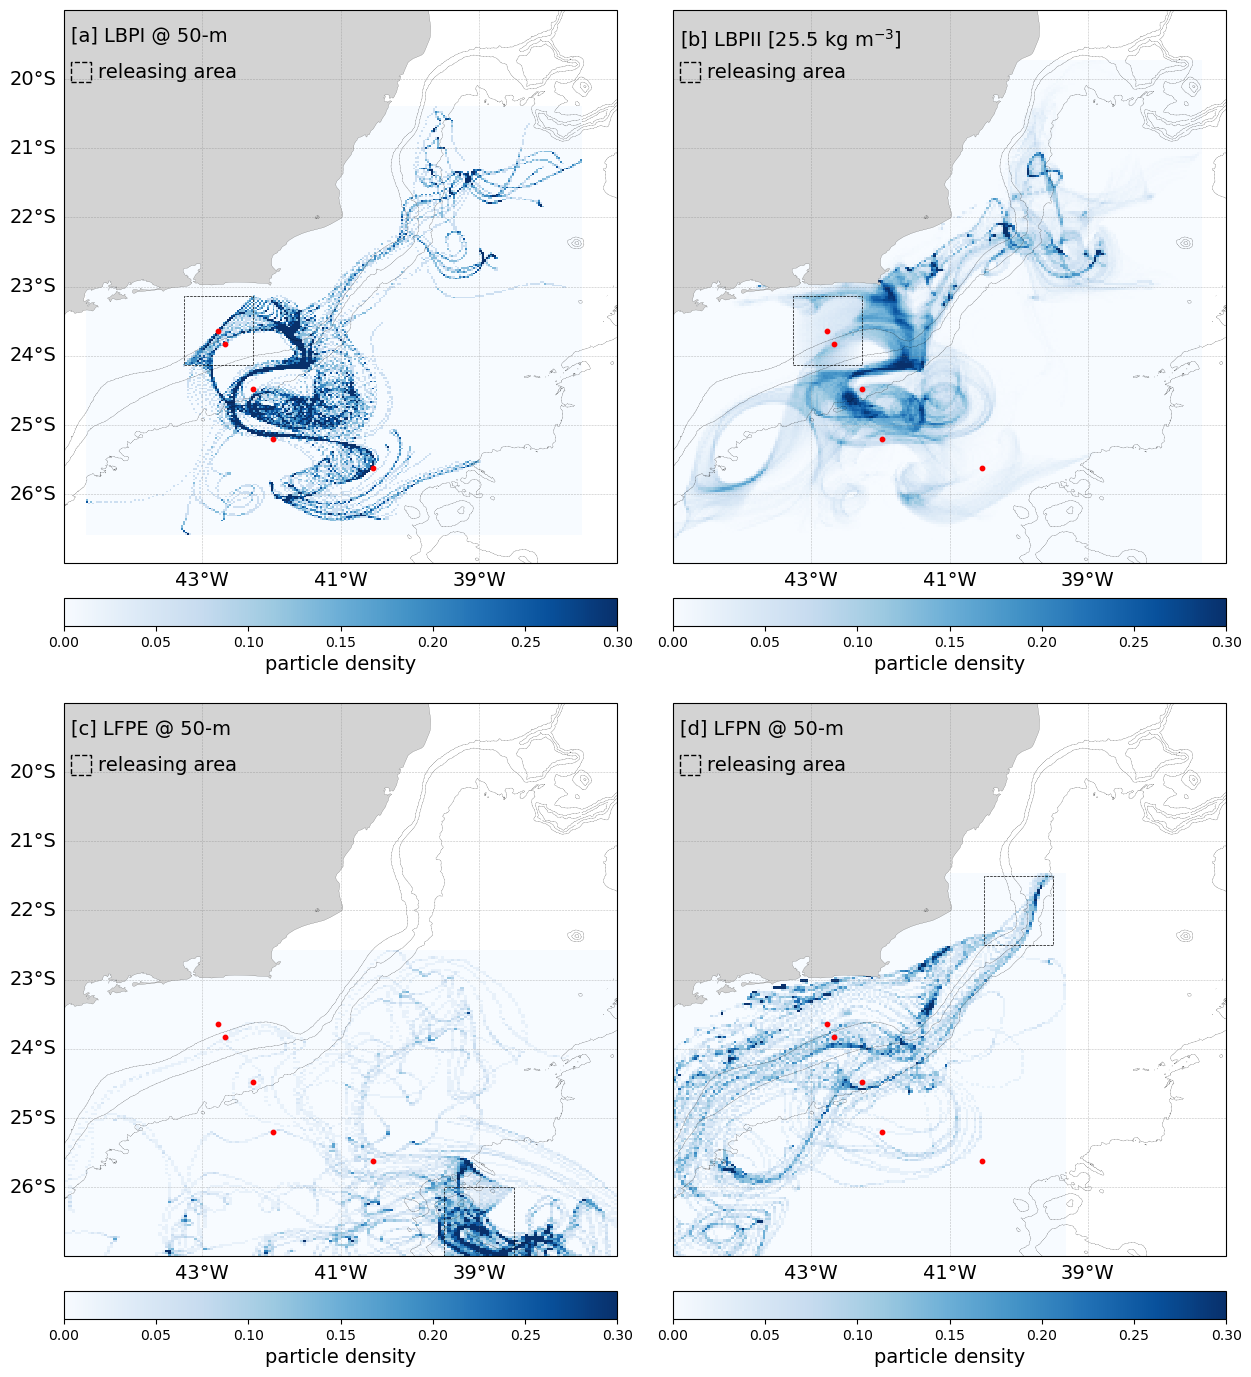

In [30]:
# glorys_current_fields = xr.open_dataset('/home/danilo/phd/thesis/chapter_colab/data/sanagu2022/glorys_current_*.nc')

fig,axes = subplots_structure(2, 2, (15,18), 4)
# titles = ['[a] back propagation @ 50-m', '[b] Isopycnal surface advection [25.5]', '[b] east release @ 75-m' ,'[c] north release @ 75-m']
titles = ['[a] LBPI @ 50-m', r'[b] LBPII [25.5 kg m$^{-3}$]', '[c] LFPE @ 50-m' ,'[d] LFPN @ 50-m']
# titles = ['[a] LBPI', '[b] LBPII', '[c] LFPE', '[d] LFPN']
maxvalues = [0.3, 0.3, 0.3, 0.3]

cont = 0

for key,ax in zip(experiments.keys(), axes):
    p = experiments[key]['outfile']

    # x,y,H = get_hist2d(p, bins=180, normalize=True)
    # _ = ax.pcolormesh(x, y, H, cmap='Blues', vmin=0, vmax=maxvalues[cont])
    # cb = plt.colorbar(_, location='bottom', pad=.05)
    # cb.set_label('particle density', fontsize=14)
    
    lons = p.lon.values[~np.isnan(p.lon.values)].ravel()
    lats = p.lat.values[~np.isnan(p.lat.values)].ravel()
    _ = ax.hist2d(lons, lats, bins=250, cmap='Blues', density=True, vmin=0, vmax=maxvalues[cont])
    cb = plt.colorbar(_[-1], location='bottom', pad=.05)
    cb.set_label('particle density', fontsize=14)
    
    ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

    states_provinces = cfeature.NaturalEarthFeature(
            category='physical',name='coastline',scale='10m',
            facecolor='lightgray')
    ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

    ### CONFIGURING MERIDIANS AND PARALLELS
    gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                    color='gray', alpha=0.5, linestyle='--',
                    xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
                    ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)
    
    if cont in [0,2]:
        gl.xlabels_top = False
        gl.ylabels_right = False
    else:
        gl.xlabels_top = False
        gl.ylabels_right = False
        gl.ylabels_left = False

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
    gl.xlabel_style = {'color': 'black', 'fontsize': '14'}
    
    # plotting selected profiles locations
    for cast,values in dict_casts.items():
        prof = values['prof']
        str_time = values['time'].strftime("%m/%d")
        xlon = values['xlon']
        ylat = values['ylat']

        ax.scatter(xlon, ylat, c='r', s=10)

    lon_min = experiments[key]['center_launch'][0]-0.5
    lon_max = experiments[key]['center_launch'][0]+0.5
    lat_min = experiments[key]['center_launch'][1]-0.5
    lat_max = experiments[key]['center_launch'][1]+0.5
    ax.add_patch(Rectangle(xy=(lon_min, lat_min),
                            width=(lon_max - lon_min),
                            height=(lat_max - lat_min),
                            facecolor='none',
                            edgecolor='k',
                            linestyle='--',
                            linewidth=0.5,
                            transform=ccrs.PlateCarree()
                        ))
    
    # ax.set_title(titles[cont], loc='left', fontsize=14, y=0.90)
    ax.text(-44.9, -19.25, titles[cont], fontsize=14, ha='left', va='top')
    # ax.scatter(-44.7, -19.9, marker='*', c='lime', s=100, zorder=10, edgecolor='k')
    ax.text(-44.5, -19.9, 'releasing area', fontsize=14, ha='left', va='center')

    legend_square = Rectangle(
        (-44.9, -20.05),
        0.3, 0.3,        # menor
        edgecolor="black",
        facecolor="none",
        linewidth=1, 
        linestyle='--',
        zorder=10
    )
    ax.add_patch(legend_square)

    bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -2000, -4000], 
                             colors=('k'), linewidths=(0.2), linestyles=('--'))
    
    cont += 1

plt.subplots_adjust(hspace=-0.0, wspace=.1)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_lagrangian_analysis.png', bbox_inches="tight", dpi=300)

TODO::

Coisas para melhorar na figura acima:

- arrumar a forma que indico a região de lançamento das partículas
- talvez remover o experimento LBPII
- colocar colorbar dentro do continente para salvar espaço?

# Investigating Lagrangian results

- trying to quantify the pathways for the LFPN case
- understand if the pathways are associated with a mean state condition (alongshelf pathway) or eddy activity (cross-shelf)
- assuming that alongshelf pathway drives a faster advection into a region of interest, while the eddy activity pathway will lead to a slow pathway
- 

*Overview of this analysis for the manuscript*

**Assumptions: alongshelf pathway drives a faster advection into the region of interest, while the eddy activity pathway affect the advection leading a slow pathway.**


**Goal:** using time and distance to find relationship with the along and cross-shelf pathways:

- **Method:** The time and distance covered by each particle since the relesing up to entering the region of interest were calculated. The median of both values were used to classify two regimes: a fast and short regime, related with the alongshelf pathway, and a slow and long regime, related to the cross-shelf pathway.
- **Result:** Approximately 31% of the particles reached the target region through fast and short pathways, indicative of more direct advection, whereas 21% followed slower and longer trajectories, suggesting retention and recirculation before arrival.

**Question:** How much particles enter the region of interest through the southern and eastern boundaries?

- **Method:** Entry sides were determined based on the boundary crossed between the last position outside and the first position inside the target region, ensuring an unambiguous classification for all particles entering the box.
- **Result:** Fast pathways predominantly enter the target region through the eastern boundary (100%), advected by the Brazil Current non-meandering state, whereas slow pathways exhibit a more isotropic distribution of entry points (84% and 16% by eastern and southern boundaries), suggesting enhanced mesoscale control.

**Question:** Does the particles with slow regime is affected significantly by the eddy activity prior reaching the region of interest?

- **Method:** Using GLORYS12V1, estimate EKE and then interpolate the EKE value for the particles position when entering the ROI (lat,lon,time)
- **Result:** Slow and long pathways spend a significantly larger fraction of their lifetime in regions of elevated eddy kinetic energy compared to fast and short pathways (Mann-Whitney U-Test 202, p-value < 0.001).



Sensibility of this analysis

- Performing the above analysis with 100 or 10000 particles does not change much in the statistics and values computed.

In [34]:
ds = xr.open_zarr('../data/lagrangean/smax_from_north_cmems.zarr').compute()

In [35]:
import numpy as np

def haversine(lon1, lat1, lon2, lat2):
    """
    Distância Haversine em metros
    """
    R = 6371e3  # raio da Terra [m]

    lon1, lat1, lon2, lat2 = map(np.deg2rad, [lon1, lat1, lon2, lat2])

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [49]:
# defining as region of interest the seeding box of the backpropagation experiment

key = 'smax_from_backpropag_cmems'
lon_min = experiments[key]['center_launch'][0]-0.5
lon_max = experiments[key]['center_launch'][0]+0.5
lat_min = experiments[key]['center_launch'][1]-0.8
lat_max = experiments[key]['center_launch'][1]+1

print(f"lon range: {lon_min, lon_max}")
print(f"lat range: {lat_min, lat_max}")

lon range: (-43.268, -42.268)
lat range: (-24.44, -22.64)


In [37]:
import numpy as np
import xarray as xr

def get_distance(ds):
    lat = ds.lat
    lon = ds.lon
    
    dstep = haversine(
        lon.shift(obs=1),
        lat.shift(obs=1),
        lon,
        lat
    )
    dist_cum = dstep.cumsum(dim="obs")
    ds["dist_cum"] = dist_cum
    ds["dist_cum"].attrs["units"] = "m"
    ds["dist_cum"].attrs["description"] = "Cumulative horizontal distance traveled since release"
    return ds

def time_and_distance_to_box(ds, lon_min, lon_max, lat_min, lat_max,
                             time_var="time"):
    """
    Calcula tempo (dias) e distância cumulativa até a primeira entrada
    em um box geográfico, e retorna também os índices necessários para
    truncar as trajetórias no momento da entrada.

    Retorna
    -------
    time_to_box_days : xarray.DataArray (npart)
    dist_to_box      : xarray.DataArray (npart)
    first_idx        : xarray.DataArray (npart)  -> índice inteiro da 1ª entrada
    ever_inside      : xarray.DataArray (npart)  -> True se entrou no box
    """
    ds = get_distance(ds)

    # 1. Máscara espacial
    inside_box = (
        (ds.lon >= lon_min) & (ds.lon <= lon_max) &
        (ds.lat >= lat_min) & (ds.lat <= lat_max)
    )

    # 2. Primeiro índice de entrada (inteiro)
    first_idx = inside_box.argmax(dim="obs")

    # 3. Partículas que realmente entram
    ever_inside = inside_box.any(dim="obs")

    # 4. Tempo físico e distância no instante de entrada
    t_entry = ds[time_var].isel(obs=first_idx)
    dist_entry = ds.dist_cum.isel(obs=first_idx)

    # 5. Mascarar partículas que nunca entraram
    t_entry = t_entry.where(ever_inside)
    dist_entry = dist_entry.where(ever_inside)

    # 6. Tempo físico no lançamento
    t0 = ds[time_var].isel(obs=0)

    # 7. Tempo até o box (em dias)
    time_to_box = t_entry - t0

    if np.issubdtype(ds[time_var].dtype, np.datetime64):
        time_to_box_days = time_to_box / np.timedelta64(1, "D")
    else:
        time_to_box_days = time_to_box / 86400.0  # assume segundos

    return time_to_box_days, dist_entry, first_idx, ever_inside

In [38]:

# get the time and distance by each particle until they reach the box.
# Here I am using the releasing box from the backpropagation experiment
time_days, dist_m, first_idx, ever_inside = time_and_distance_to_box(
    ds,
    lon_min=lon_min, lon_max=lon_max,
    lat_min=lat_min, lat_max=lat_max,
    time_var="time"
)

obs_idx = xr.DataArray(
    np.arange(ds.dims["obs"]),
    dims="obs"
)

before_entry = obs_idx <= first_idx

lon_until_box = ds.lon.where(before_entry & ever_inside)
lat_until_box = ds.lat.where(before_entry & ever_inside)

#################
#################
#################
# finding the pathways for fast and slow advection, then computing the proportion on each regime
valid = (~np.isnan(time_days)) & (~np.isnan(dist_m))

t = time_days.where(valid)
d = dist_m.where(valid)

# using median
t_med = t.median()
d_med = d.median()

fast_short = (t <= t_med) & (d <= d_med)
slow_long  = (t >  t_med) & (d >  d_med)

ds["fast_short"] = fast_short
ds["slow_long"]  = slow_long

lon_fast = ds.lon.where(fast_short)
lat_fast = ds.lat.where(fast_short)

lon_slow = ds.lon.where(slow_long)
lat_slow = ds.lat.where(slow_long)

n_total = valid.sum().item()

n_fast = fast_short.sum().item()
n_slow = slow_long.sum().item()

pct_fast = 100 * n_fast / n_total
pct_slow = 100 * n_slow / n_total

print(f"How many particles reached the ROI? {n_total}")
print(f"fast pathway: {n_fast} ({pct_fast:.1f}%)")
print(f"slow pathway:  {n_slow} ({pct_slow:.1f}%)")
print(f"Tmedian {t_med.item()}, Dmeadian {d_med.item()/1000}")

How many particles reached the ROI? 94
fast pathway: 28 (29.8%)
slow pathway:  24 (25.5%)
Tmedian 18.25, Dmeadian 368.44325


In [39]:
print('How long it takes to reach the box (max)?')
print(f"{time_days.max().item()} dias") 

How long it takes to reach the box (max)?
51.25 dias


Plotting the trajectories classified by fast/slow pathway

In [40]:
lon_fast_until = ds.lon.where(before_entry & ever_inside & fast_short)
lat_fast_until = ds.lat.where(before_entry & ever_inside & fast_short)

lon_slow_until = ds.lon.where(before_entry & ever_inside & slow_long)
lat_slow_until = ds.lat.where(before_entry & ever_inside & slow_long)


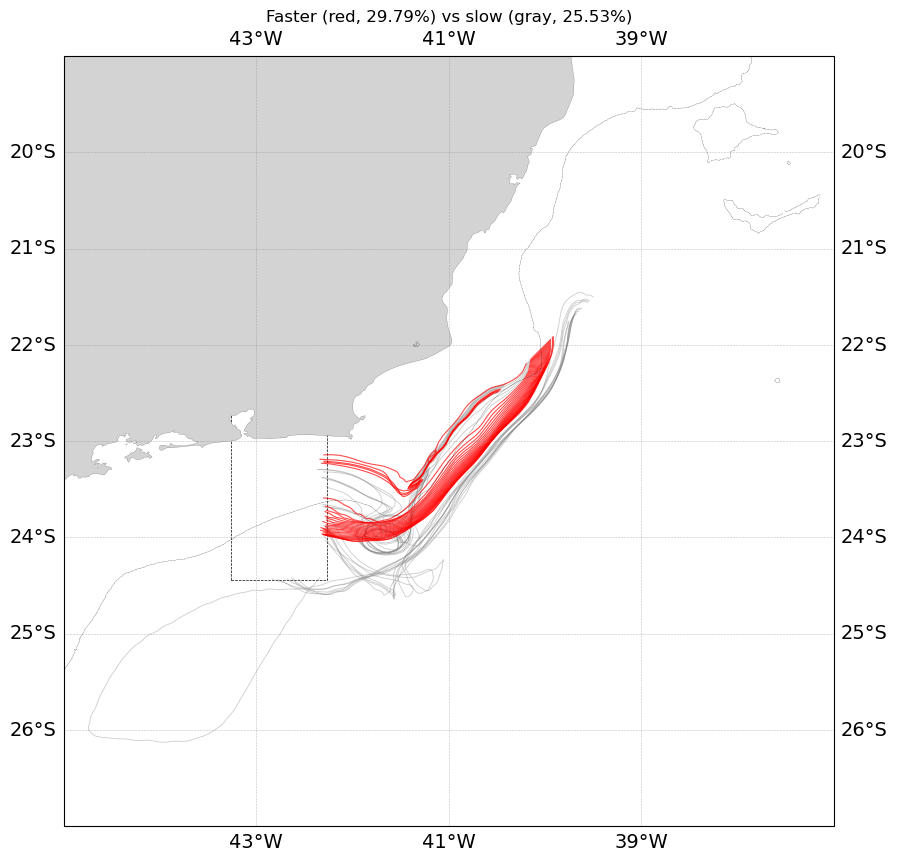

In [41]:
zoomed_extent = [-45, -37, -27, -19]

fig,axes = subplots_structure(1, 1, (10,10), 1)
ax = axes[0]

ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

states_provinces = cfeature.NaturalEarthFeature(
        category='physical',name='coastline',scale='10m',
        facecolor='lightgray')
ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

### CONFIGURING MERIDIANS AND PARALLELS
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                color='gray', alpha=0.5, linestyle='--',
                xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
                ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
gl.xlabel_style = {'color': 'black', 'fontsize': '14'}

# lentas primeiro (fundo)
ax.plot(
    lon_slow_until.T,
    lat_slow_until.T,
    color="gray",
    alpha=0.4,
    linewidth=0.6,
    label="Lentas & longas"
)

# rápidas por cima
ax.plot(
    lon_fast_until.T,
    lat_fast_until.T,
    color="red",
    alpha=0.7,
    linewidth=0.8,
    label="Rápidas & curtas"
)

ax.add_patch(Rectangle(xy=(lon_min, lat_min),
                        width=(lon_max - lon_min),
                        height=(lat_max - lat_min),
                        facecolor='none',
                        edgecolor='k',
                        linestyle='--',
                        linewidth=0.5,
                        transform=ccrs.PlateCarree()
                    ))

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, ], 
                         colors=('k'), linewidths=(0.2), linestyles=('--'))

_ = plt.title(f"Faster (red, {pct_fast:0.2f}%) vs slow (gray, {pct_slow:0.2f}%)")

In [42]:
print("Average time in days:")
print("  fast:", t.where(fast_short).mean().item())
print("  slow:", t.where(slow_long).mean().item())

Average time in days:
  fast: 9.25
  slow: 22.65625


In [43]:
print("Average cumulative distance in km:")
print("  fast:", d.where(fast_short).mean().item()/1000)
print("  slow:", d.where(slow_long).mean().item()/1000)

Average cumulative distance in km:
  fast: 334.3954375
  slow: 541.2274375


**Next, understand which boundary of the ROI particles enter**

Initially, the entry side of each particle was determined based on the first position inside the target box, using a spatial tolerance relative to the box boundaries. While this approach correctly identified whether a particle entered the box, it led to an apparent loss of particles when computing entry-side percentages, with 15–30% of trajectories remaining unclassified.

This behavior is not a conceptual error but a geometric and numerical artifact of Lagrangian trajectories. Particles often cross a boundary between two discrete time steps, such that the first position recorded inside the box is already located well within the interior and therefore not sufficiently close to any boundary. This effect is amplified when the model time step is large, velocities are high, or particles enter through corners or along diagonal paths.

To resolve this issue, the entry side must be defined based on the boundary actually crossed, rather than the position inside the box. This was achieved by identifying, for each particle, the last position outside the box and the first position inside the box, and classifying the entry side according to which boundary was crossed between these two consecutive positions.

This crossing-based definition ensures that: every particle that enters the box is unambiguously assigned to exactly one boundary, the classification is independent of spatial tolerances, entry-side percentages sum to 100% when normalized by particles that effectively enter the region, and the diagnostic is physically meaningful and numerically robust.

This adjustment is essential for correctly interpreting transport pathways and linking entry statistics to underlying dynamical processes such as mean advection and mesoscale modulation.


In [44]:
# find the % of particles entering the ROI by each side of the ROI (mostly interested on the east and south faces, which will indicate along and cross-shelf)
lon_entry = ds.lon.isel(obs=first_idx).where(ever_inside)
lat_entry = ds.lat.isel(obs=first_idx).where(ever_inside)

lon_entry_fast = lon_entry.where(fast_short)
lat_entry_fast = lat_entry.where(fast_short)

lon_entry_slow = lon_entry.where(slow_long)
lat_entry_slow = lat_entry.where(slow_long)

entered = ~np.isnan(lon_entry.values)

fast_entered = fast_short.values & entered
slow_entered = slow_long.values & entered

# Get the position in and out the box to find the crossing boundary
lon_in  = ds.lon.isel(obs=first_idx).values
lat_in  = ds.lat.isel(obs=first_idx).values

lon_out = ds.lon.isel(obs=first_idx - 1).values
lat_out = ds.lat.isel(obs=first_idx - 1).values


# Classifying the entering side
entry_side = np.full(lon_in.shape, "", dtype=object)
entry_side[(lon_out < lon_min) & (lon_in >= lon_min)] = "West"
entry_side[(lon_out > lon_max) & (lon_in <= lon_max)] = "East"
entry_side[(lat_out < lat_min) & (lat_in >= lat_min)] = "South"
entry_side[(lat_out > lat_max) & (lat_in <= lat_max)] = "North"


# masking by side to help in further analysis
west  = entry_side == "West"
east  = entry_side == "East"
south = entry_side == "South"
north = entry_side == "North"

def percent(mask, regime_entered):
    return 100 * np.sum(mask & regime_entered) / np.sum(regime_entered)


print("\nFAST & short (considering only particles entering the ROI):")
print(f" West : {percent(west, fast_entered):.1f}%")
print(f" East : {percent(east, fast_entered):.1f}%")
print(f" South: {percent(south, fast_entered):.1f}%")
print(f" North: {percent(north, fast_entered):.1f}%")

print(" Just to check: FAST:",
      percent(west, fast_entered)
    + percent(east, fast_entered)
    + percent(south, fast_entered)
    + percent(north, fast_entered)
)


# --------------------------------------------------
# 8) Resultados finais — SLOW
# --------------------------------------------------

print("\nSLOW & long (considering only particles entering the ROI):")
print(f" West : {percent(west, slow_entered):.1f}%")
print(f" East : {percent(east, slow_entered):.1f}%")
print(f" South: {percent(south, slow_entered):.1f}%")
print(f" North: {percent(north, slow_entered):.1f}%")

print(" Just to check: SLOW:",
      percent(west, slow_entered)
    + percent(east, slow_entered)
    + percent(south, slow_entered)
    + percent(north, slow_entered)
)


FAST & short (considering only particles entering the ROI):
 West : 0.0%
 East : 100.0%
 South: 0.0%
 North: 0.0%
 Just to check: FAST: 100.0

SLOW & long (considering only particles entering the ROI):
 West : 0.0%
 East : 70.8%
 South: 29.2%
 North: 0.0%
 Just to check: SLOW: 100.0


Text(0.5, 1.0, 'Entry-side distribution')

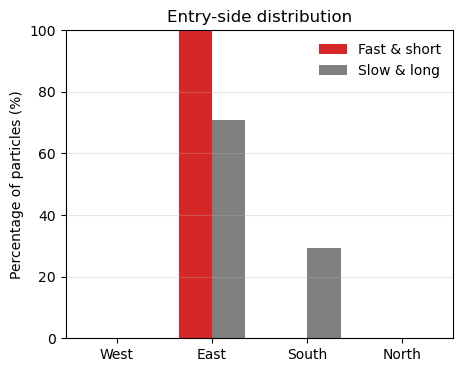

In [45]:
labels = ["West", "East", "South", "North"]

fast_perc = [percent(west, fast_entered), percent(east, fast_entered), percent(south, fast_entered), percent(north, fast_entered)]
slow_perc = [percent(west, slow_entered), percent(east, slow_entered), percent(south, slow_entered), percent(north, slow_entered)]

import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(labels))
w = 0.35

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - w/2, fast_perc, w,
       label="Fast & short",
       color="tab:red")

ax.bar(x + w/2, slow_perc, w,
       label="Slow & long",
       color="gray")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Percentage of particles (%)")
ax.set_ylim(0, 100)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)

ax.set_title("Entry-side distribution")

# caption: Percentage of particles entering the region of interest through each boundary, computed considering only particles that effectively enter the box and separated by pathway.

Next, it make sense to cross tha particles pathway with the 50-m depth currents, in terms of eddy kinectic energy (for slow pathways) and mean state Brazil Current (for faster pathways)

U = 121.0
p-value = 4.0890260409670224e-05
Fração média de tempo em alta EKE:
 Fast: 0.2763157894736842
 Slow: 0.37107571560480146

Mediana:
 Fast: 0.26315789473684215
 Slow: 0.3781163434903047


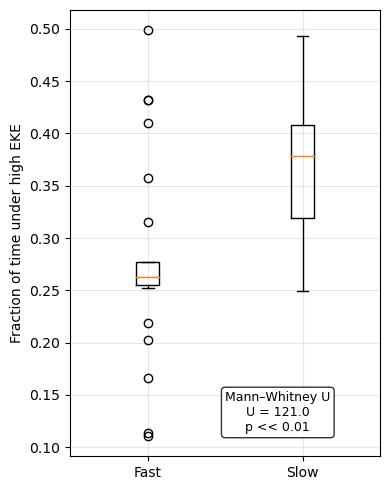

In [46]:
ds_uv = xr.open_mfdataset('../data/glorys/glorys_current_*.nc')

idz = np.argmin(np.abs(ds_uv.depth.values - 50))
ds_uv = ds_uv.isel(depth=idz).squeeze()

# mean flow
u_mean = ds_uv.uo.mean(dim="time")
v_mean = ds_uv.vo.mean(dim="time")

spd_mean = np.sqrt(u_mean**2 + v_mean**2)

# eddies
u_prime = ds_uv.uo - u_mean
v_prime = ds_uv.vo - v_mean
EKE = 0.5 * (u_prime**2 + v_prime**2)
EKE_mean = EKE.mean("time")

eke_thresh = EKE_mean.quantile(0.75) # 75º percentil 
EKE_on_traj = EKE.interp( longitude=ds.lon, latitude=ds.lat, time=ds.time ) 
high_EKE = EKE_on_traj > eke_thresh 
frac_time_high_EKE = high_EKE.mean(dim="obs") 
frac_fast = frac_time_high_EKE.where(fast_short) 
frac_slow = frac_time_high_EKE.where(slow_long)

EKE_entry = EKE_mean.interp(
    longitude=lon_entry,
    latitude=lat_entry
)

EKE_fast = EKE_entry.where(fast_short)
EKE_slow = EKE_entry.where(slow_long)

from scipy.stats import mannwhitneyu

x_fast = frac_fast.dropna("trajectory").values
x_slow = frac_slow.dropna("trajectory").values

U, p = mannwhitneyu(
    x_fast,
    x_slow,
    alternative="less"  # fast < slow
)

print("U =", U)
print("p-value =", p)


print("Fração média de tempo em alta EKE:")
print(" Fast:", frac_fast.compute().mean().item())
print(" Slow:", frac_slow.compute().mean().item()) 
print("\nMediana:") 
print(" Fast:", frac_fast.compute().median().item())
print(" Slow:", frac_slow.compute().median().item())

plt.figure(figsize=(4,5))

plt.boxplot(
    [frac_fast.dropna("trajectory"),
     frac_slow.dropna("trajectory")],
    labels=["Fast", "Slow"]
)

plt.ylabel("Fraction of time under high EKE")
plt.grid(alpha=0.3)

# texto do teste estatístico
textstr = (
    "Mann–Whitney U\n"
    f"U = {U}\n"
    "p << 0.01"
)

# canto inferior direito
plt.text(
    0.67, 0.05, textstr,
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="bottom",
    horizontalalignment="center",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()

In [47]:
# zoomed_extent = [-45, -37, -27, -19]

# fig,axes = subplots_structure(2, 1, (16,10), 2)

# ax = axes[0]

# ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

# states_provinces = cfeature.NaturalEarthFeature(
#         category='physical',name='coastline',scale='10m',
#         facecolor='lightgray')
# ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

# ### CONFIGURING MERIDIANS AND PARALLELS
# gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
#                 color='gray', alpha=0.5, linestyle='--',
#                 xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
#                 ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)


# gl.xformatter = LONGITUDE_FORMATTER
# gl.yformatter = LATITUDE_FORMATTER
# gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
# gl.xlabel_style = {'color': 'black', 'fontsize': '14'}

# # # corrente média
# # _ = ax.quiver(
# #     u_mean.longitude, u_mean.latitude,
# #     u_mean, v_mean,
# #     scale=5, width=0.002, alpha=0.5
# # )

# spd_mean.plot.pcolormesh(ax=ax, cmap=cmo.speed, cbar_kwargs={'location': 'bottom', 'pad': 0.05})


# # # pontos de entrada
# # ax.scatter(lon_entry_slow, lat_entry_slow,
# #             color="gray", s=15, alpha=0.6, label="Slow")

# ax.scatter(lon_entry_fast, lat_entry_fast,
#             color="red", s=20, alpha=0.8, label="Fast")

# ax.set_title('mean state')


# ax = axes[1]

# ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

# states_provinces = cfeature.NaturalEarthFeature(
#         category='physical',name='coastline',scale='10m',
#         facecolor='lightgray')
# ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

# ### CONFIGURING MERIDIANS AND PARALLELS
# gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
#                 color='gray', alpha=0.5, linestyle='--',
#                 xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
#                 ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)

# gl.xformatter = LONGITUDE_FORMATTER
# gl.yformatter = LATITUDE_FORMATTER
# gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
# gl.xlabel_style = {'color': 'black', 'fontsize': '14'}

# EKE_mean.plot.pcolormesh(ax=ax, cmap='magma', cbar_kwargs={'location': 'bottom', 'pad': 0.05})

# plt.scatter(lon_entry_fast, lat_entry_fast,
#             color="cyan", s=20, label="Fast")

# ax.set_title('EKE')

**Insights**

Slow and long pathways spend a significantly larger fraction of their lifetime in regions of elevated eddy kinetic energy compared to fast and short pathways, 
indicating enhanced retention and recirculation by mesoscale activity.

The fraction of time spent in high-EKE regions is significantly larger for slow pathways compared to fast pathways (Mann–Whitney U test, U = 202.5, p < 0.001). 
This indicate enhanced exposure to mesoscale turbulence for particles following slower and longer trajectories.

Sensibility of this analysis

- Performing the above analysis with 100 or 10000 particles does not change much in the statistics and values computed.

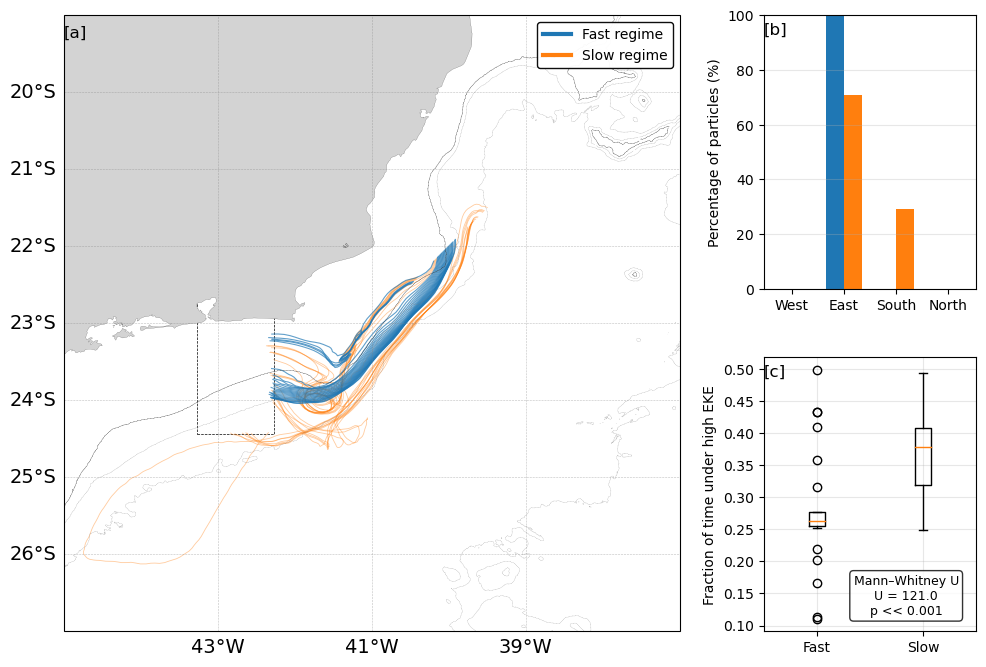

In [48]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D


zoomed_extent = [-45, -37, -27, -19]

fig = plt.figure(figsize=(12, 8))

gs = GridSpec(
    nrows=2,
    ncols=3,
    figure=fig,
    width_ratios=[2.2, 2.2, 1.6],   # mapa largo + coluna direita
    height_ratios=[1, 1],
    wspace=0.25,
    hspace=0.25
)

ax = fig.add_subplot(
    gs[:, :2],  # ocupa duas linhas e duas colunas
    projection=ccrs.PlateCarree()
)
ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

states_provinces = cfeature.NaturalEarthFeature(
        category='physical',name='coastline',scale='10m',
        facecolor='lightgray')
ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

### CONFIGURING MERIDIANS AND PARALLELS
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                color='gray', alpha=0.5, linestyle='--',
                xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
                ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)

gl.xlabels_top = False
gl.ylabels_right = False

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
gl.xlabel_style = {'color': 'black', 'fontsize': '14'}

# lentas primeiro (fundo)
ax.plot(
    lon_slow_until.T,
    lat_slow_until.T,
    color="tab:orange",
    alpha=0.4,
    linewidth=0.6
)

# rápidas por cima
ax.plot(
    lon_fast_until.T,
    lat_fast_until.T,
    color="tab:blue",
    alpha=0.7,
    linewidth=0.8
)

ax.add_patch(Rectangle(xy=(lon_min, lat_min),
                        width=(lon_max - lon_min),
                        height=(lat_max - lat_min),
                        facecolor='none',
                        edgecolor='k',
                        linestyle='--',
                        linewidth=0.5,
                        transform=ccrs.PlateCarree()
                    ))

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -2000, -4000], 
                         colors=('gray'), linewidths=(0.2), linestyles=('--'))

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, ], 
                         colors=('k'), linewidths=(0.2), linestyles=('--'))

ax.set_title('[a]', loc='left', y=0.95)


legend_elements = [
    Line2D(
        [0], [0],
        color="tab:blue",
        lw=3,
        label="Fast regime"
    ),
    Line2D(
        [0], [0],
        color="tab:orange",
        lw=3,
        label="Slow regime"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=10,
    frameon=True,
    framealpha=0.95,
    edgecolor="black"
)

########################################################

ax = fig.add_subplot(gs[0, 2])

x = np.arange(len(labels))
w = 0.35

ax.bar(x - w/2, fast_perc, w,
       label="Fast & short",
       color="tab:blue")

ax.bar(x + w/2, slow_perc, w,
       label="Slow & long",
       color="tab:orange")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Percentage of particles (%)")
ax.set_ylim(0, 100)

# ax.legend(frameon=False, fontsize=10)
ax.grid(axis="y", alpha=0.3)

ax.set_title("[b]", loc='left', y=0.9)

# caption: Percentage of particles entering the region of interest through each boundary, computed considering only particles that effectively enter the box and separated by pathway.

ax = fig.add_subplot(gs[1, 2])

ax.boxplot(
    [frac_fast.dropna("trajectory"),
     frac_slow.dropna("trajectory")],
    labels=["Fast", "Slow"]
)

ax.set_ylabel("Fraction of time under high EKE")
ax.grid(alpha=0.3)

textstr = (
    "Mann–Whitney U\n"
    f"U = {U}\n"
    "p << 0.001"
)

# canto inferior direito
plt.text(
    0.67, 0.05, textstr,
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="bottom",
    horizontalalignment="center",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

ax.set_title('[c]', loc='left', y=0.90)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"../figures/manuscript/00_manuscript_forwardLag_analysis.png",
           dpi=150,
           bbox_inches='tight')

Figure X - (a) Fast (blue) and slow (orange) regimes pathways of particles that entered the region of interest (dashed black square), for the experiment LFPN only. Note we have extended the region of interest further north to consider particles advected over the shelf and along the shelfbreak and south to consider the shelf break, since in this last case particles drifting along the shelf might be injected into the shelf. (b) Percentage of particles entering the region of interest through each boundary, computed considering only particles that effectively enter the box and separated by pathway, the colors follow the same from (a). (c) Fraction of time particles were found under high EKE activity for the fast  (left) and slow (right) regimes. The Mann-Whitney U-Test indicate particles for the slow regime are under eddy activity influence.

# Figures to answer reviewer

In [8]:
import pandas as pd
import numpy as np
def get_location(_ds, _profile):

    # extract info from parcels output
    lons = _ds.lon.values
    lats = _ds.lat.values
    times = _ds.time.values

    # extract info from observations
    target_lon = _profile['xlon']
    target_lat = _profile['ylat']
    target_time = _profile['time'] #.strftime('%Y-%m-%d')

    # identify nearest point
    distances = np.sqrt((lats - target_lat)**2 + (lons - target_lon)**2)
    closest_index = np.argmin(distances)

    # return time
    return pd.to_datetime(times[closest_index]) - target_time

In [9]:
key = 'smax_from_backpropag_cmems'
ds = experiments[key]['outfile']

parcel_time = {}
for cast in dict_casts.keys():
    # print(dict_casts[cast]['time']
    parcel_time[cast] = []
    for traj in range(100):
        _ds = ds.isel(trajectory=traj)
        parcel_time[cast].append(get_location(_ds, dict_casts[cast]))

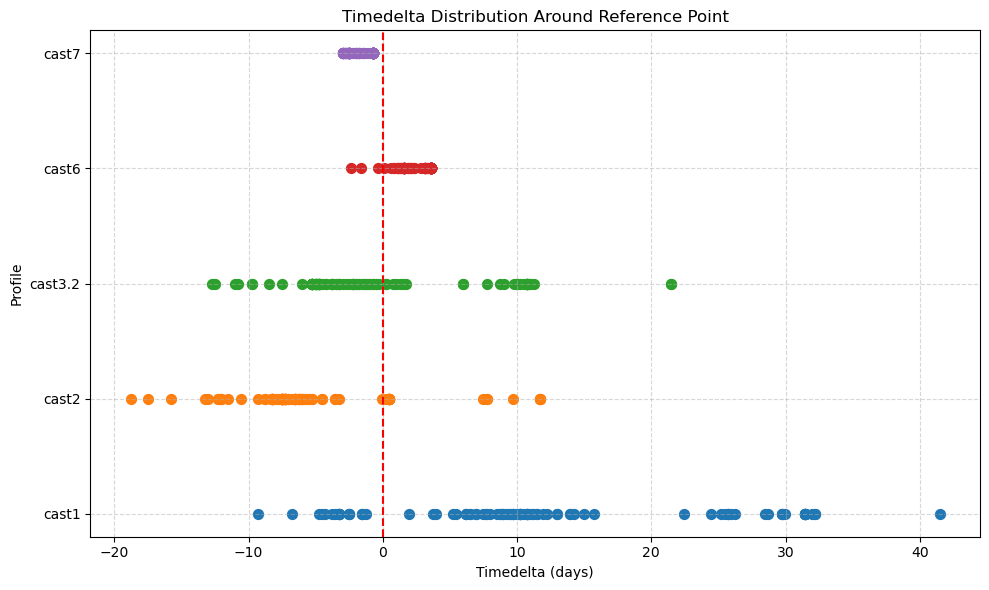

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

data = parcel_time

# # Convert to DataFrame for plotting
# records = []
# for profile, td_list in data.items():
#     for td in td_list:
#         records.append({'profile': profile, 'days': td.total_seconds() / (24 * 3600)})

# df = pd.DataFrame(records)

# # Plot
# plt.figure(figsize=(10, 6))
# sns.stripplot(data=df, x='days', y='profile', jitter=True, size=6)

# plt.axvline(0, color='red', linestyle='--', label='Reference point')  # Optional reference line
# plt.xlabel('Timedelta (days)')
# plt.ylabel('Profile')
# plt.title('Timedelta Distribution Around Reference Point')
# plt.legend()
# plt.tight_layout()
# plt.show()

# Prepare data for plotting
profiles = list(data.keys())
y_positions = range(len(profiles))

plt.figure(figsize=(10, 6))

for y, profile in zip(y_positions, profiles):
    tds = data[profile]
    # Convert to days
    days = [td.total_seconds() / (24 * 3600) for td in tds]
    plt.scatter(days, [y]*len(days), label=profile, s=50)

# Formatting
plt.yticks(y_positions, profiles)
plt.axvline(0, color='red', linestyle='--', label='Reference Point')
plt.xlabel('Timedelta (days)')
plt.ylabel('Profile')
plt.title('Timedelta Distribution Around Reference Point')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

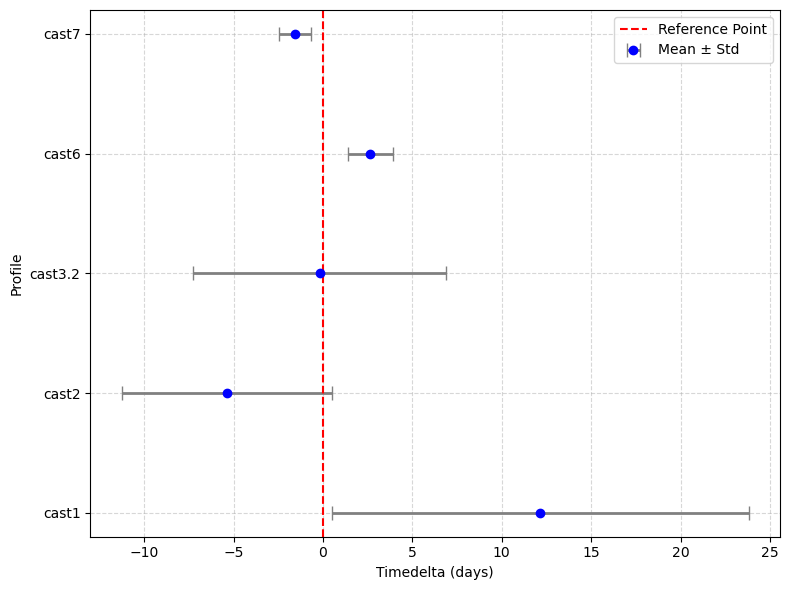

In [11]:
# Prepare data
profiles = list(data.keys())
means = []
stds = []

for profile in profiles:
    tds = data[profile]
    days = np.array([td.total_seconds() / (24 * 3600) for td in tds])
    means.append(np.mean(days))
    stds.append(np.std(days))

# Plot
plt.figure(figsize=(8, 6))
y_positions = np.arange(len(profiles))

plt.errorbar(
    means, y_positions,
    xerr=stds,
    fmt='o',
    color='blue',
    ecolor='gray',
    elinewidth=2,
    capsize=5,
    label='Mean ± Std'
)

# Formatting
plt.axvline(0, color='red', linestyle='--', label='Reference Point')
plt.yticks(y_positions, profiles)
plt.xlabel('Timedelta (days)')
plt.ylabel('Profile')
# plt.title('Mean Timedelta with Error Bars')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()